#### PyTorch Fundamentals

Core data structure of PyTorch is a tensor. A multidimensional array with a shape and a data type. Kind of like an array, but with support for GPU and support auto-differentiation.

Creation of a tensor

In [2]:
import torch

# let's create a 2 x 3 array (tensor)
X = torch.tensor([[1, 2, 3], [4, 5, 6]])
X

tensor([[1, 2, 3],
        [4, 5, 6]])

Info

In [3]:
X.shape

torch.Size([2, 3])

In [4]:
X.dtype

torch.int64

Indexing

In [5]:
X[0, 1]

tensor(2)

In [6]:
X[:, 1]

tensor([2, 5])

#### Hardware Acceleration

In [7]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cuda'

Now let's create a tensor on that GPU

In [8]:
M = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
M = M.to(device)

In [9]:
M.device

device(type='cuda', index=0)

In [10]:
M = torch.tensor([[1., 2., 3.], [4., 5., 6.]], device=device)

Run something on the gpu

In [11]:
R = M @ M.T
R

tensor([[14., 32.],
        [32., 77.]], device='cuda:0')

In [12]:
M = torch.rand((1000, 1000))  # on the CPU
%timeit M @ M.T

6.18 ms ± 74.8 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [13]:
M = torch.rand((1000, 1000), device="cuda")  # on the GPU
%timeit M @ M.T

225 μs ± 2.03 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


#### Autograd

PyTorch comes with an efficient implementation of reverse-mode auto-differentiation, called `autograd`, which stands for `automatic gradients`.

Consider a simple function, f(x) = x^2. Derivitive of this is f'(x) = 2x so eval on f(x) and f'(x) should be 25 and 10.

In [14]:
x = torch.tensor(5.0, requires_grad=True)
f = x ** 2
f

tensor(25., grad_fn=<PowBackward0>)

In [15]:
f.backward()
x.grad

tensor(10.)

After computing the gradients, you generally want to perform a gradien descent step by subtracting a fraction of the gradients from the model variables.

In [16]:
learning_rate = 0.1
with torch.no_grad():
    x -= learning_rate * x.grad

or use `detach()` which is detached from the computational graph.

In [17]:
x_detached = x.detach()
x_detached -= learning_rate * x.grad

Before repeating the process (forward pass + backward pass + gradient descent step), it is essential to zero out the gradients of every model params.

In [18]:
x.grad.zero_()

tensor(0.)

Putting it all together, this how the training loop looks like:

In [19]:
learning_rate = 0.1
x = torch.tensor(5.0, requires_grad=True)
for iteration in range(100):
    f = x ** 2 # forward pass
    f.backward() # backward pass
    with torch.no_grad():
        x -= learning_rate * x.grad # gradient descent step

    x.grad.zero_()

#### Implementing Linear Regression

In [20]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

Let's cast our dataset to FloatTensor

In [21]:
X_train = torch.FloatTensor(X_train)
X_valid = torch.FloatTensor(X_valid)
X_test = torch.FloatTensor(X_test)
means = X_train.mean(dim=0, keepdims=True)
stds = X_train.std(dim=0, keepdims=True)
X_train = (X_train - means) / stds
X_valid = (X_valid - means) / stds
X_test = (X_test - means) / stds

And convert our targets as well

In [22]:
y_train = torch.FloatTensor(y_train).reshape(-1, 1)
y_valid = torch.FloatTensor(y_valid).reshape(-1, 1)
y_test = torch.FloatTensor(y_test).reshape(-1, 1)

Let's create the params for our model

In [23]:
torch.manual_seed(42)
n_features = X_train.shape[1] # there are 8 input features
w = torch.rand((n_features, 1), requires_grad=True) # weights
b = torch.tensor(0., requires_grad=True) # bias

Next, let's train our model.

In [24]:
learning_rate = 0.4
n_epochs = 20
for epoch in range(n_epochs):
    y_pred = X_train @ w + b
    loss = ((y_pred - y_train) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad
        w.grad.zero_()
        b.grad.zero_()
    print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}")

Epoch 1/20, Loss: 7.792580604553223
Epoch 2/20, Loss: 1.3588199615478516
Epoch 3/20, Loss: 0.84256911277771
Epoch 4/20, Loss: 0.7366544604301453
Epoch 5/20, Loss: 0.6970381140708923
Epoch 6/20, Loss: 0.6746658086776733
Epoch 7/20, Loss: 0.6581473350524902
Epoch 8/20, Loss: 0.6443582773208618
Epoch 9/20, Loss: 0.6323144435882568
Epoch 10/20, Loss: 0.6216264367103577
Epoch 11/20, Loss: 0.6120853424072266
Epoch 12/20, Loss: 0.6035464406013489
Epoch 13/20, Loss: 0.5958940982818604
Epoch 14/20, Loss: 0.5890297889709473
Epoch 15/20, Loss: 0.5828677415847778
Epoch 16/20, Loss: 0.577332079410553
Epoch 17/20, Loss: 0.5723556280136108
Epoch 18/20, Loss: 0.5678789019584656
Epoch 19/20, Loss: 0.5638489723205566
Epoch 20/20, Loss: 0.5602186918258667


Now we can predict

In [25]:
X_new = X_test[:3] # pretend these are new instances
with torch.no_grad():
    y_pred = X_new @ w + b # use the trained params to make predictions
y_pred

tensor([[0.8684],
        [1.6626],
        [2.7272]])

Now let's rewrite using higher-level API.

In [26]:
import torch.nn as nn  # by convention, this module is usually imported this way
torch.manual_seed(42)  # to get reproducible results
model = nn.Linear(in_features=n_features, out_features=1)

In [27]:
model.bias

Parameter containing:
tensor([0.3117], requires_grad=True)

In [28]:
model.weight

Parameter containing:
tensor([[ 0.2703,  0.2935, -0.0828,  0.3248, -0.0775,  0.0713, -0.1721,  0.2076]],
       requires_grad=True)

We can call the model as a function

In [29]:
model(X_train[:2])

tensor([[-0.4718],
        [ 0.1131]], grad_fn=<AddmmBackward0>)

We have our model, now we need to create an optimizer to update the model params and must also choose a loss function

In [30]:
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()

Let's define a simple train function. Notice it is simpler than before.

In [31]:
def train_bgd(model, optimizer, criterion, X_train, y_train, n_epochs):
    for epoch in range(n_epochs):
        y_pred = model(X_train)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}")

In [32]:
train_bgd(model, optimizer, mse, X_train, y_train, n_epochs)

Epoch 1/20, Loss: 4.3378496170043945
Epoch 2/20, Loss: 0.780293345451355
Epoch 3/20, Loss: 0.6253840923309326
Epoch 4/20, Loss: 0.6060433387756348
Epoch 5/20, Loss: 0.5956299304962158
Epoch 6/20, Loss: 0.5873566269874573
Epoch 7/20, Loss: 0.5802990198135376
Epoch 8/20, Loss: 0.5741382241249084
Epoch 9/20, Loss: 0.5687100887298584
Epoch 10/20, Loss: 0.5639079213142395
Epoch 11/20, Loss: 0.5596510767936707
Epoch 12/20, Loss: 0.5558737516403198
Epoch 13/20, Loss: 0.5525194406509399
Epoch 14/20, Loss: 0.5495391488075256
Epoch 15/20, Loss: 0.5468900203704834
Epoch 16/20, Loss: 0.544533908367157
Epoch 17/20, Loss: 0.5424376726150513
Epoch 18/20, Loss: 0.5405716300010681
Epoch 19/20, Loss: 0.5389097332954407
Epoch 20/20, Loss: 0.5374288558959961


In [33]:
X_new = X_test[:3]  # pretend these are new instances
with torch.no_grad():
    y_pred = model(X_new)  # use the trained model to make predictions
y_pred

tensor([[0.8061],
        [1.7116],
        [2.6973]])

#### Implementing a Regression MLP

The MLP is a simple stack of modules - two hidden layers and one output layer.

In [34]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(n_features, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
)

In [35]:
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()
train_bgd(model, optimizer, mse, X_train, y_train, n_epochs)

Epoch 1/20, Loss: 5.045480251312256
Epoch 2/20, Loss: 2.0523128509521484
Epoch 3/20, Loss: 1.0039883852005005
Epoch 4/20, Loss: 0.8570139408111572
Epoch 5/20, Loss: 0.7740675210952759
Epoch 6/20, Loss: 0.7225848436355591
Epoch 7/20, Loss: 0.6893726587295532
Epoch 8/20, Loss: 0.6669032573699951
Epoch 9/20, Loss: 0.6507739424705505
Epoch 10/20, Loss: 0.6383935213088989
Epoch 11/20, Loss: 0.6281994581222534
Epoch 12/20, Loss: 0.6193399429321289
Epoch 13/20, Loss: 0.6113173365592957
Epoch 14/20, Loss: 0.6038705706596375
Epoch 15/20, Loss: 0.5968308448791504
Epoch 16/20, Loss: 0.5901119112968445
Epoch 17/20, Loss: 0.5836468935012817
Epoch 18/20, Loss: 0.5774064064025879
Epoch 19/20, Loss: 0.5713555812835693
Epoch 20/20, Loss: 0.565444827079773


we've trained a neural net.

#### Implementing Mini-Batch Gradient Descent Using DataLoaders

In [36]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)

We have a larger model and we have the tools to train it batch at a time. Let's use the GPU.

In [37]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(n_features, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
)
model = model.to(device, non_blocking=True)

Write a generic train loop

In [38]:
def train(model, optimizer, criterion, train_loader, n_epochs):
    model.train()
    for epoch in range(n_epochs):
        total_loss = 0.
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        mean_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {mean_loss:.4f}")

In [39]:
train(model, optimizer, mse, train_loader, n_epochs)

Epoch 1/20, Loss: 5.0460
Epoch 2/20, Loss: 5.0443
Epoch 3/20, Loss: 5.0456
Epoch 4/20, Loss: 5.0457
Epoch 5/20, Loss: 5.0450
Epoch 6/20, Loss: 5.0452
Epoch 7/20, Loss: 5.0449
Epoch 8/20, Loss: 5.0449
Epoch 9/20, Loss: 5.0459
Epoch 10/20, Loss: 5.0460
Epoch 11/20, Loss: 5.0456
Epoch 12/20, Loss: 5.0449
Epoch 13/20, Loss: 5.0461
Epoch 14/20, Loss: 5.0452
Epoch 15/20, Loss: 5.0456
Epoch 16/20, Loss: 5.0454
Epoch 17/20, Loss: 5.0455
Epoch 18/20, Loss: 5.0460
Epoch 19/20, Loss: 5.0451
Epoch 20/20, Loss: 5.0456


#### Model Evaluation

We will write an eval function.

In [40]:
def evaluate(model, data_loader, metric_fn, aggregate_fn=torch.mean):
    model.eval()
    metrics = []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric = metric_fn(y_pred, y_batch)
            metrics.append(metric)
    return aggregate_fn(torch.stack(metrics))

Now let's build a `TensorDataset` and a `DataLoader` for our validation set, and pass it to our `evaluate()` function to compute the validation MSE.

In [41]:
valid_dataset = TensorDataset(X_valid, y_valid)
valid_loader = DataLoader(valid_dataset, batch_size=32)
valid_mse = evaluate(model, valid_loader, mse)
valid_mse

tensor(4.8635, device='cuda:0')

If we want to use RMSE instead of MSE, there are built-ins but it's easy enough to write.

In [42]:
def rmse(y_pred, y_true):
    return ((y_pred - y_true) ** 2).mean().sqrt()

evaluate(model, valid_loader, rmse)

tensor(2.1945, device='cuda:0')

In [43]:
valid_mse.sqrt()

tensor(2.2053, device='cuda:0')

the RMSE should be equal to the square root of the MSE, however, we got a diff. result

We calculated the RMSE over each batch and then computed the mean for all these batches. That's not equivalent to computing the RMSE over the whole validation set.

In [44]:
evaluate(model,
         valid_loader,
         mse,
         aggregate_fn=lambda metrics: torch.sqrt(torch.mean(metrics))
         )

tensor(2.2053, device='cuda:0')

Instead of this, we can use `TorchMetrics`.

In [45]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset() # reset the metric at the beginning
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch) # update at each iter
    return metric.compute()

In [46]:
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
evaluate_tm(model, valid_loader, rmse)

tensor(2.2054, device='cuda:0')

We can now update the train function to evaluate our performance during training and validation of each epoch.

Again, if the performance on the trianing set is much better than the validation set, your model is probably overfitting the trianing set or there is a bug in the dataset.

It is easier to detect by plotting.

Epoch 1/20, train loss: 0.7826, train metric: 0.8847, valid metric: 0.6690
Epoch 2/20, train loss: 0.4362, train metric: 0.6605, valid metric: 0.6099
Epoch 3/20, train loss: 0.3930, train metric: 0.6269, valid metric: 0.6145
Epoch 4/20, train loss: 0.3759, train metric: 0.6132, valid metric: 0.5963
Epoch 5/20, train loss: 0.3649, train metric: 0.6040, valid metric: 0.5911
Epoch 6/20, train loss: 0.3598, train metric: 0.5999, valid metric: 0.5965
Epoch 7/20, train loss: 0.3530, train metric: 0.5941, valid metric: 0.6061
Epoch 8/20, train loss: 0.3495, train metric: 0.5911, valid metric: 0.6043
Epoch 9/20, train loss: 0.3455, train metric: 0.5877, valid metric: 0.5723
Epoch 10/20, train loss: 0.3416, train metric: 0.5846, valid metric: 0.6043
Epoch 11/20, train loss: 0.3401, train metric: 0.5831, valid metric: 0.5882
Epoch 12/20, train loss: 0.3362, train metric: 0.5799, valid metric: 0.5738
Epoch 13/20, train loss: 0.3352, train metric: 0.5788, valid metric: 0.5873
Epoch 14/20, train lo

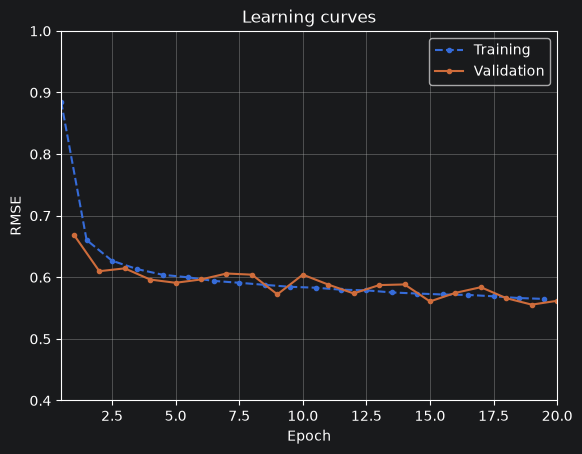

In [47]:
import matplotlib.pyplot as plt
import numpy as np

def train2(model, optimizer, criterion, metric, train_loader, valid_loader, n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for X_batch, y_batch in train_loader:
            model.train()
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(train_loader)
        history["train_losses"].append(mean_loss)
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

torch.manual_seed(42)
learning_rate = 0.01
model = nn.Sequential(
    nn.Linear(n_features, 50), nn.ReLU(),
    nn.Linear(50, 40), nn.ReLU(),
    nn.Linear(40, 30), nn.ReLU(),
    nn.Linear(30, 1)
)
model = model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train2(model, optimizer, mse, rmse, train_loader, valid_loader,
                 n_epochs)

# Since we compute the training metric
plt.plot(np.arange(n_epochs) + 0.5, history["train_metrics"], ".--",
         label="Training")
plt.plot(np.arange(n_epochs) + 1.0, history["valid_metrics"], ".-",
         label="Validation")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.grid()
plt.title("Learning curves")
plt.axis([0.5, 20, 0.4, 1.0])
plt.legend()
plt.show()

#### Building Nonsequential Models Using Custom Modules

One example of a nosequential neural network is a wide & deep neural net. It connects all or part of the inputs directly to the output layer. This makes it possible for the neural network to learn both deep patterns and simple rules. In contrast, a regular MLP forces all the data to flow through the full stack of layers.

In [48]:
class WideAndDeep(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features, 50),
            nn.ReLU(),
            nn.Linear(50, 40),
            nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features, 1)

    def forward(self, X):
        deep_output = self.deep_stack(X)
        wide_and_deep = torch.concat([X, deep_output], dim=1)
        return self.output_layer(wide_and_deep)

In [49]:
torch.manual_seed(42)
model = WideAndDeep(n_features).to(device)
learning_rate = 0.002 # the model changed, so did the optimal lr

In case you want to send a subset of the features through the wide path and a different subset (possibly overlapping) through the deep path, we can split the inputs inside the forward func.

In [50]:
class WideAndDeepV2(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features, 50),
            nn.ReLU(),
            nn.Linear(50, 40),
            nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features, 1)

    def forward(self, X):
        X_wide = X[:, :5]
        X_deep = X[:, 2:]
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_output], dim=1)
        return self.output_layer(wide_and_deep)

#### Building Models with Multiple Inputs

Let us adjust the class

In [51]:
class WideAndDeepV3(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features - 2, 50),
            nn.ReLU(),
            nn.Linear(50, 40),
            nn.ReLU(),
            nn.Linear(40, 30),
            nn.ReLU(),
        )
        self.output_layer = nn.Linear(30 + 5, 1)

    def forward(self, X_wide, X_deep):
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_output], dim=1)
        return self.output_layer(wide_and_deep)

In [52]:
torch.manual_seed(42)
train_data_wd = TensorDataset(X_train[:, :5], X_train[:, 2:], y_train)
train_loader_wd = DataLoader(train_data_wd, batch_size=32, shuffle=True)
valid_data_wd = TensorDataset(X_valid[:, :5], X_valid[:, 2:], y_valid)
valid_loader_wd = DataLoader(valid_data_wd, batch_size=32)
test_data_wd = TensorDataset(X_test[:, :5], X_test[:, 2:], y_test)
test_loader_wd = DataLoader(test_data_wd, batch_size=32)

In [53]:
def evaluate_multi_in(model, data_loader, metric):
    model.eval()
    metric.reset()  # reset the metric at the beginning
    with torch.no_grad():
        for X_batch_wide, X_batch_deep, y_batch in data_loader:
            X_batch_wide = X_batch_wide.to(device)
            X_batch_deep = X_batch_deep.to(device)
            y_batch = y_batch.to(device)
            y_pred = model(X_batch_wide, X_batch_deep)
            metric.update(y_pred, y_batch)  # update it at each iteration
    return metric.compute()  # compute the final result at the end

def train_multi_in(model, optimizer, criterion, metric, train_loader,
                   valid_loader, n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for *X_batch_inputs, y_batch in train_loader:
            model.train()
            X_batch_inputs = [X.to(device) for X in X_batch_inputs]
            y_batch = y_batch.to(device)
            y_pred = model(*X_batch_inputs)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(train_loader)
        history["train_losses"].append(mean_loss)
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_multi_in(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

torch.manual_seed(42)
learning_rate = 0.01
model = WideAndDeepV3(n_features).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train_multi_in(model, optimizer, mse, rmse, train_loader_wd,
                         valid_loader_wd, n_epochs)

Epoch 1/20, train loss: 0.8366, train metric: 0.9148, valid metric: 0.6892
Epoch 2/20, train loss: 0.4627, train metric: 0.6803, valid metric: 0.6455
Epoch 3/20, train loss: 0.4319, train metric: 0.6572, valid metric: 0.6374
Epoch 4/20, train loss: 0.4259, train metric: 0.6525, valid metric: 0.6512
Epoch 5/20, train loss: 0.4120, train metric: 0.6420, valid metric: 0.6305
Epoch 6/20, train loss: 0.4040, train metric: 0.6356, valid metric: 0.6287
Epoch 7/20, train loss: 0.4005, train metric: 0.6330, valid metric: 0.6252
Epoch 8/20, train loss: 0.3976, train metric: 0.6306, valid metric: 0.6158
Epoch 9/20, train loss: 0.3883, train metric: 0.6229, valid metric: 0.7407
Epoch 10/20, train loss: 0.3866, train metric: 0.6218, valid metric: 0.6064
Epoch 11/20, train loss: 0.3752, train metric: 0.6125, valid metric: 0.5975
Epoch 12/20, train loss: 0.3704, train metric: 0.6087, valid metric: 0.5887
Epoch 13/20, train loss: 0.3675, train metric: 0.6062, valid metric: 0.5981
Epoch 14/20, train lo

With multiple inputs it is easy to make mistakes. For this, you can define a custom dataset that returns a dictionary from input names to input values

In [54]:
class WideAndDeepDataset(torch.utils.data.Dataset):
    def __init__(self, X_wide, X_deep, y):
        self.X_wide = X_wide
        self.X_deep = X_deep
        self.y = y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        input_dict = {"X_wide": self.X_wide[idx], "X_deep": self.X_deep[idx]}
        return input_dict, self.y[idx]

Then create the datasets and data loaders

In [55]:
torch.manual_seed(42)
train_data_named = WideAndDeepDataset(X_wide=X_train[:, :5], X_deep=X_train[:, 2:], y=y_train)
train_loader_named = DataLoader(train_data_named, batch_size=32, shuffle=True)
valid_data_named = WideAndDeepDataset(X_wide=X_valid[:, :5], X_deep=X_valid[:, 2:], y=y_valid)
valid_loader_named = DataLoader(valid_data_named, batch_size=32)
test_data_named = WideAndDeepDataset(X_wide=X_test[:, :5], X_deep=X_test[:, 2:], y=y_test)
test_loader_named = DataLoader(test_data_named, batch_size=32)

In [56]:
def evaluate_named(model, data_loader, metric):
    model.eval()
    metric.reset()  # reset the metric at the beginning
    with torch.no_grad():
        for inputs, y_batch in data_loader:
            inputs = {name: X.to(device) for name, X in inputs.items()}
            y_batch = y_batch.to(device)
            y_pred = model(X_wide=inputs["X_wide"], X_deep=inputs["X_deep"])
            metric.update(y_pred, y_batch)
    return metric.compute()  # compute the final result at the end

def train_named(model, optimizer, criterion, metric, train_loader,
                   valid_loader, n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for inputs, y_batch in train_loader:
            model.train()
            inputs = {name: X.to(device) for name, X in inputs.items()}
            y_batch = y_batch.to(device)
            y_pred = model(**inputs)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(train_loader)
        history["train_losses"].append(mean_loss)
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_named(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

torch.manual_seed(42)
learning_rate = 0.01
model = WideAndDeepV3(n_features).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train_named(model, optimizer, mse, rmse, train_loader_named,
                      valid_loader_named, n_epochs)

Epoch 1/20, train loss: 0.8366, train metric: 0.9148, valid metric: 0.6892
Epoch 2/20, train loss: 0.4627, train metric: 0.6803, valid metric: 0.6455
Epoch 3/20, train loss: 0.4319, train metric: 0.6572, valid metric: 0.6374
Epoch 4/20, train loss: 0.4259, train metric: 0.6525, valid metric: 0.6512
Epoch 5/20, train loss: 0.4120, train metric: 0.6420, valid metric: 0.6305
Epoch 6/20, train loss: 0.4040, train metric: 0.6356, valid metric: 0.6287
Epoch 7/20, train loss: 0.4005, train metric: 0.6330, valid metric: 0.6252
Epoch 8/20, train loss: 0.3976, train metric: 0.6306, valid metric: 0.6158
Epoch 9/20, train loss: 0.3883, train metric: 0.6229, valid metric: 0.7407
Epoch 10/20, train loss: 0.3866, train metric: 0.6218, valid metric: 0.6064
Epoch 11/20, train loss: 0.3752, train metric: 0.6125, valid metric: 0.5975
Epoch 12/20, train loss: 0.3704, train metric: 0.6087, valid metric: 0.5887
Epoch 13/20, train loss: 0.3675, train metric: 0.6062, valid metric: 0.5981
Epoch 14/20, train lo

#### Building Models with Multiple Outputs

There are many use cases where you may need a neural net with multiple outputs:
- The task may demand it. For instance, you may want to locate and classify the main object in a picture. This is both a regression task and a classification task.
- Similarly, you may have multiple independent tasks based on the same data. For example, you could perform multitask classification on pictures of faces, using one output to classify the person's facial expression and another output to identify whether they are wearing glasses.
- Another use case is regularization. For example, you may want to add an auxiliary output in a neural network architecture to ensure that the underlying part of the network learns something useful on its own.

In [57]:
class WideAndDeepV4(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features - 2, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
            nn.Linear(40, 30), nn.ReLU(),
        )
        self.output_layer = nn.Linear(30 + 5, 1)
        self.aux_output_layer = nn.Linear(30, 1)

    def forward(self, X_wide, X_deep):
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_output], dim=1)
        main_output = self.output_layer(wide_and_deep)
        aux_output = self.aux_output_layer(deep_output)
        return main_output, aux_output
import torchmetrics

def evaluate_multi_out(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for inputs, y_batch in data_loader:
            inputs = {name: X.to(device) for name, X in inputs.items()}
            y_batch = y_batch.to(device)
            y_pred, _ = model(**inputs)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train_multi_out(model, optimizer, criterion, metric, train_loader,
                   valid_loader, n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for inputs, y_batch in train_loader:
            model.train()
            inputs = {name: X.to(device) for name, X in inputs.items()}
            y_batch = y_batch.to(device)
            y_pred, y_pred_aux = model(**inputs)
            main_loss = criterion(y_pred, y_batch)
            aux_loss = criterion(y_pred_aux, y_batch)
            loss = 0.8 * main_loss + 0.2 * aux_loss
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(train_loader)
        history["train_losses"].append(mean_loss)
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_multi_out(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

torch.manual_seed(42)
learning_rate = 0.01
model = WideAndDeepV4(n_features).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train_multi_out(model, optimizer, mse, rmse, train_loader_named,
                          valid_loader_named, n_epochs)

Epoch 1/20, train loss: 1.0693, train metric: 0.9506, valid metric: 0.7085
Epoch 2/20, train loss: 0.5817, train metric: 0.6946, valid metric: 0.6607
Epoch 3/20, train loss: 0.5009, train metric: 0.6581, valid metric: 0.6425
Epoch 4/20, train loss: 0.4690, train metric: 0.6497, valid metric: 0.6654
Epoch 5/20, train loss: 0.4503, train metric: 0.6420, valid metric: 0.6338
Epoch 6/20, train loss: 0.4385, train metric: 0.6371, valid metric: 0.6560
Epoch 7/20, train loss: 0.4314, train metric: 0.6329, valid metric: 0.6193
Epoch 8/20, train loss: 0.4248, train metric: 0.6301, valid metric: 0.6166
Epoch 9/20, train loss: 0.4115, train metric: 0.6201, valid metric: 0.6454
Epoch 10/20, train loss: 0.4087, train metric: 0.6200, valid metric: 0.5940
Epoch 11/20, train loss: 0.4075, train metric: 0.6198, valid metric: 0.5954
Epoch 12/20, train loss: 0.3914, train metric: 0.6077, valid metric: 0.6072
Epoch 13/20, train loss: 0.3847, train metric: 0.6033, valid metric: 0.5816
Epoch 14/20, train lo

#### Building an Image Classifier with PyTorch

In [58]:
import torchvision
import torchvision.transforms.v2 as T

toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_valid_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=True, download=True, transform=toTensor)
test_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=False, download=True, transform=toTensor)

torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(
    train_and_valid_data, [55_000, 5_000])

We transformed to tensor as the dataset comes in PIL by default. Next, we load the dataset.

In [59]:
torch.manual_seed(42)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

In [60]:
X_sample, y_sample = train_data[0]
X_sample.shape

torch.Size([1, 28, 28])

In [61]:
X_sample.dtype

torch.float32

In [62]:
train_and_valid_data.classes[y_sample]

'Ankle boot'

#### Building the Classifier

In [7]:
class ImageClassifier(nn.Module):
    def __init__(self, n_inputs, n_hidden1, n_hidden2, n_classes):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_inputs, n_hidden1),
            nn.ReLU(),
            nn.Linear(n_hidden1, n_hidden2),
            nn.ReLU(),
            nn.Linear(n_hidden2, n_classes)
        )

    def forward(self, X):
        return self.mlp(X)

torch.manual_seed(42)
model = ImageClassifier(n_inputs=1 * 28 * 28, n_hidden1=300, n_hidden2=100,
                        n_classes=10).to(device)
xentropy = nn.CrossEntropyLoss()

NameError: name 'nn' is not defined

In [64]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
_ = train2(model, optimizer, xentropy, accuracy, train_loader, valid_loader, n_epochs)

Epoch 1/20, train loss: 0.6059, train metric: 0.7815, valid metric: 0.8404
Epoch 2/20, train loss: 0.4055, train metric: 0.8499, valid metric: 0.8404
Epoch 3/20, train loss: 0.3629, train metric: 0.8665, valid metric: 0.8508
Epoch 4/20, train loss: 0.3354, train metric: 0.8766, valid metric: 0.8652
Epoch 5/20, train loss: 0.3149, train metric: 0.8843, valid metric: 0.8792
Epoch 6/20, train loss: 0.2988, train metric: 0.8872, valid metric: 0.8616
Epoch 7/20, train loss: 0.2855, train metric: 0.8924, valid metric: 0.8750
Epoch 8/20, train loss: 0.2747, train metric: 0.8961, valid metric: 0.8736
Epoch 9/20, train loss: 0.2638, train metric: 0.9010, valid metric: 0.8820
Epoch 10/20, train loss: 0.2526, train metric: 0.9050, valid metric: 0.8710
Epoch 11/20, train loss: 0.2455, train metric: 0.9073, valid metric: 0.8878
Epoch 12/20, train loss: 0.2355, train metric: 0.9098, valid metric: 0.8860
Epoch 13/20, train loss: 0.2289, train metric: 0.9127, valid metric: 0.8848
Epoch 14/20, train lo

In [6]:
model.eval()
X_new, y_new = next(iter(valid_loader))
X_new = X_new[:3].to(device)
with torch.no_grad():
    y_pred_logits = model(X_new)
y_pred = y_pred_logits.argmax(dim=1)  # index of the largest logit
y_pred

NameError: name 'model' is not defined

In [68]:
[train_and_valid_data.classes[index] for index in y_pred]

['Sneaker', 'Coat', 'Pullover']

Let's check whether the model made the correct predictions:

In [1]:
y_new[:3]

NameError: name 'y_new' is not defined

#### Fine-Tuning Neural Network Hyperparameters with Optuna

Let's look at an example of using Optuna to fine-tune hyperparams.

In [ ]:
import optuna

# this will be called by the optimizer
# it asks for params, uses the params to build and train a model, then returns the result
def objective(trial):
    # define ranges of fine-tuning
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-1, log=True)
    n_hidden = trial.suggest_int("n_hidden", 20, 300)

    # create model
    model = ImageClassifier(
        n_inputs=1 * 28 * 28,
        n_hidden1=n_hidden,
        n_hidden2=n_hidden,
        n_classes=10).to(device)

    # define optimizer, metrics
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    xentropy = nn.CrossEntropyLoss()
    accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10)
    accuracy = accuracy.to(device)

    # train
    history = train2(model, optimizer, xentropy, accuracy, train_loader,
                     valid_loader, n_epochs=10)
    validation_accuracy = max(history["valid_metrics"])
    return validation_accuracy

torch.manual_seed(42)
sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=5)